In [2]:
import pandas as pd
nist_spectra_df = pd.read_pickle('../../data/proc/nist20/spec_df.pkl')
nist_spectra_df.head()

,spec_id,mol_id,prec_type,inst_type,frag_mode,spec_type,ion_mode,dset,dset_spec_id,col_gas,res,ace,nce,prec_mz,peaks,ri,group_id
0,0,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035166,N2,2,8.0,NaN,1467.0061,"[(45.96, 46.35), (597.48, 51.85), (598.5, 41.3...",NaN,0
1,1,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035167,N2,2,10.0,NaN,1467.0061,"[(597.5, 50.95), (599.5, 683.32), (1449.98, 99...",NaN,0
2,2,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035168,N2,2,14.0,NaN,1467.0061,"[(537.39, 55.94), (599.5, 999.0), (600.51, 42....",NaN,0
3,3,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035169,N2,2,16.0,NaN,1467.0061,"[(597.46, 41.86), (598.5, 45.15), (599.51, 999...",NaN,0
4,4,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035170,N2,2,20.0,NaN,1467.0061,"[(598.49, 47.85), (599.5, 999.0), (600.5, 85.5...",NaN,0


In [3]:
def larger_then_prec_mz(x, tol=10.0):
    #if peaks:
    peaks = x['peaks']
    pmass = x['prec_mz']
    mz_max = max(peaks, key=lambda x: x[0])[0]
    return pmass * ( 1 + tol / 1_000_000) <= mz_max

nist_spectra_df['larger_then_pmass_peaks'] = nist_spectra_df.apply(lambda x: larger_then_prec_mz(x, 10), axis=1)

In [4]:
nist_spectra_df = nist_spectra_df[nist_spectra_df['dset'].isin(['nist20_hr'])]
nist_spectra_df.shape
print(nist_spectra_df['larger_then_pmass_peaks'].sum())

258172


In [5]:
nist_spectra_df.loc[:, 'ace'] = nist_spectra_df.apply(lambda x: round(x['prec_mz'] * x['nce'] / 500 if pd.isnull(x['ace']) else x['ace'] , 0), axis=1)
nist_spectra_df.loc[:, 'nce'] = nist_spectra_df.apply(lambda x: round(x['ace'] * 500 / x['prec_mz'] if pd.isnull(x['nce']) else x['nce'] , 0), axis=1)

In [6]:
# Group by prec_type (adducts) and count the number of spectra in each group
adduct_counts = nist_spectra_df['prec_type'].value_counts().sort_values(ascending=False)
# Display the results
print(f"Number of unique adduct types: {len(adduct_counts)}")
print("\nTop adduct types:\n")
print(adduct_counts)

Number of unique adduct types: 6091

Top adduct types:

prec_type
[M+H]+                     311072
[M-H]-                     123854
[M+H-H2O]+                  84118
[M+Na]+                     38337
[2M+H]+                     28761
                            ...  
[M+H-C2H2O-OH]+                 1
[M+H-C2H2O-NO2-H2Cl]+           1
[M+H-C7H9NO-C2H3O-CH3]+         1
[M+H-C5H8O2-2H2O]+              1
[M+H-C2H2ClO-CH3]+              1
Name: count, Length: 6091, dtype: int64


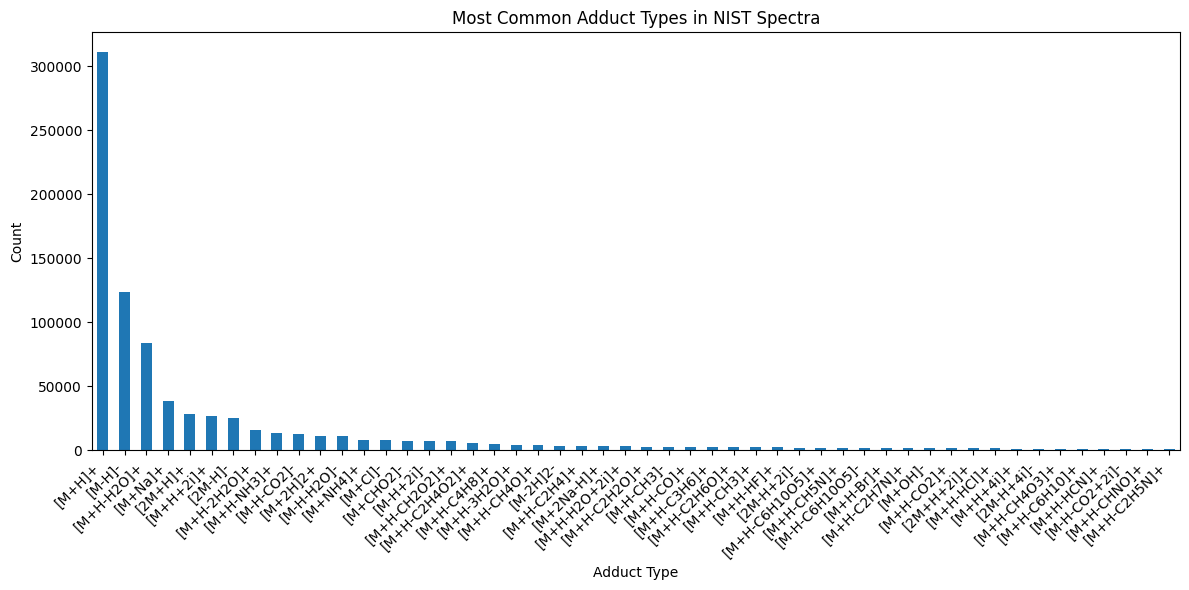

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
adduct_counts.head(50).plot(kind='bar')
plt.title('Most Common Adduct Types in NIST Spectra')
plt.ylabel('Count')
plt.xlabel('Adduct Type')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

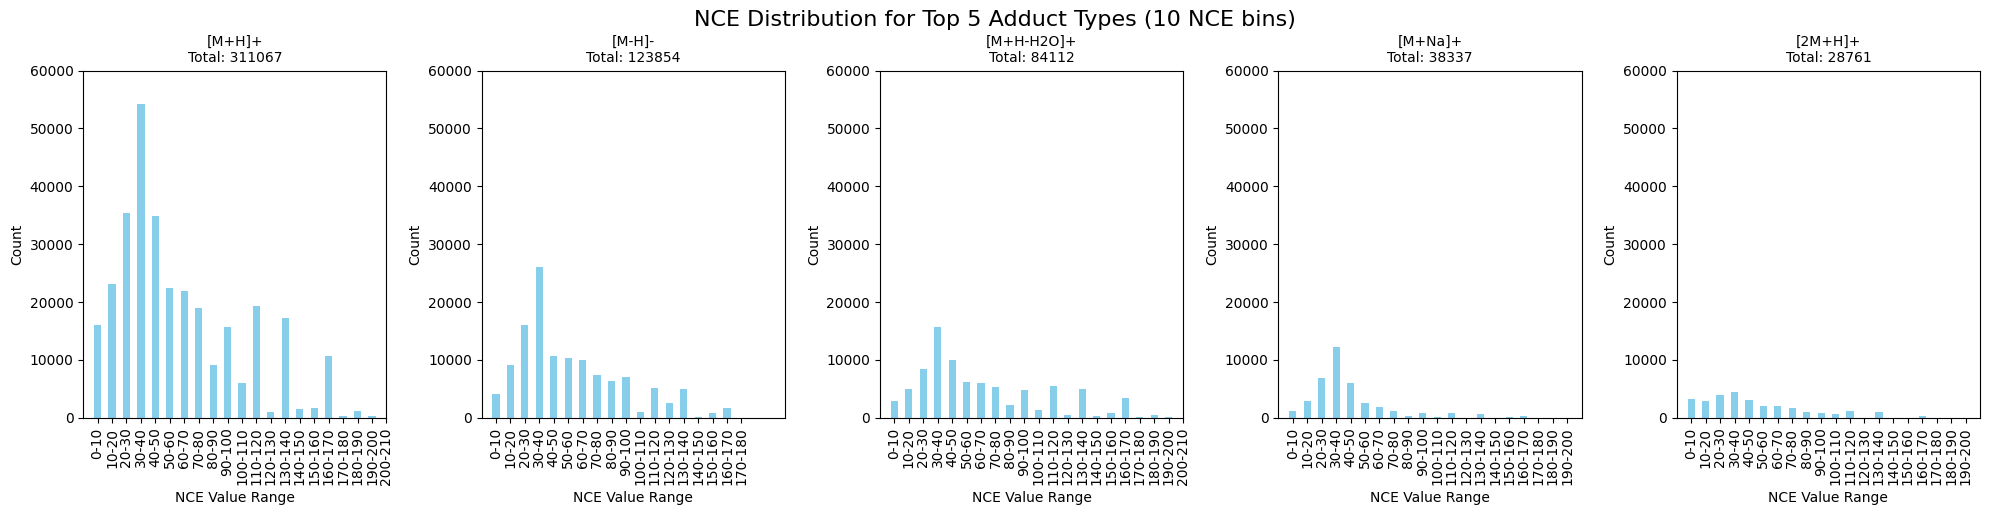

In [8]:
import numpy as np

prec_type_nce_counts = nist_spectra_df.groupby(['prec_type', 'nce']).size().unstack(fill_value=0)

# Get the sum of spectra for each adduct type across all NCEs
adduct_totals = prec_type_nce_counts.sum(axis=1).sort_values(ascending=False)
top_10_adducts = adduct_totals.head(5).index

# Create a figure with 10 subplots (2 rows, 5 columns)
fig, axes = plt.subplots(1, 5, figsize=(20, 5), sharey=False)
axes = axes.flatten()

# Define NCE bins
nce_bin_size = 10
bins = np.arange(0, 325, nce_bin_size)
bin_labels = [f"{b}-{b+nce_bin_size}" for b in bins[:-1]]

# Plot data for each of the top 10 adducts
for i, adduct in enumerate(top_10_adducts):
    # Get the NCE counts for this adduct
    nce_data = prec_type_nce_counts.loc[adduct]
    
    # Create binned data
    binned_data = {}
    for col in nce_data.index:
        bin_idx = np.digitize(col, bins) - 1
        if bin_idx >= len(bin_labels):
            continue
        bin_name = bin_labels[bin_idx]
        if bin_name not in binned_data:
            binned_data[bin_name] = 0
        binned_data[bin_name] += nce_data[col]
    
    # Convert to Series
    binned_series = pd.Series(binned_data)
    # Filter out zero counts
    binned_series = binned_series[binned_series > 0]
    
    # Plot on the corresponding subplot
    ax = axes[i]
    binned_series.plot(kind='bar', ax=ax, color='skyblue')
    
    # Set labels and title
    ax.set_title(f"{adduct}", fontsize=10)
    ax.set_xlabel('NCE Value Range')
    ax.set_ylabel('Count')
    ax.tick_params(axis='x', rotation=90)
    ax.set_ylim(0, 60_000)

    ax.set_xlim(-1, 20)
    # Add total count in the title
    total = binned_series.sum()
    ax.set_title(f"{adduct}\nTotal: {total}", fontsize=10)

# Adjust layout
plt.tight_layout()
plt.suptitle(f'NCE Distribution for Top 5 Adduct Types ({nce_bin_size} NCE bins)', fontsize=16, y=1.02)
plt.show()

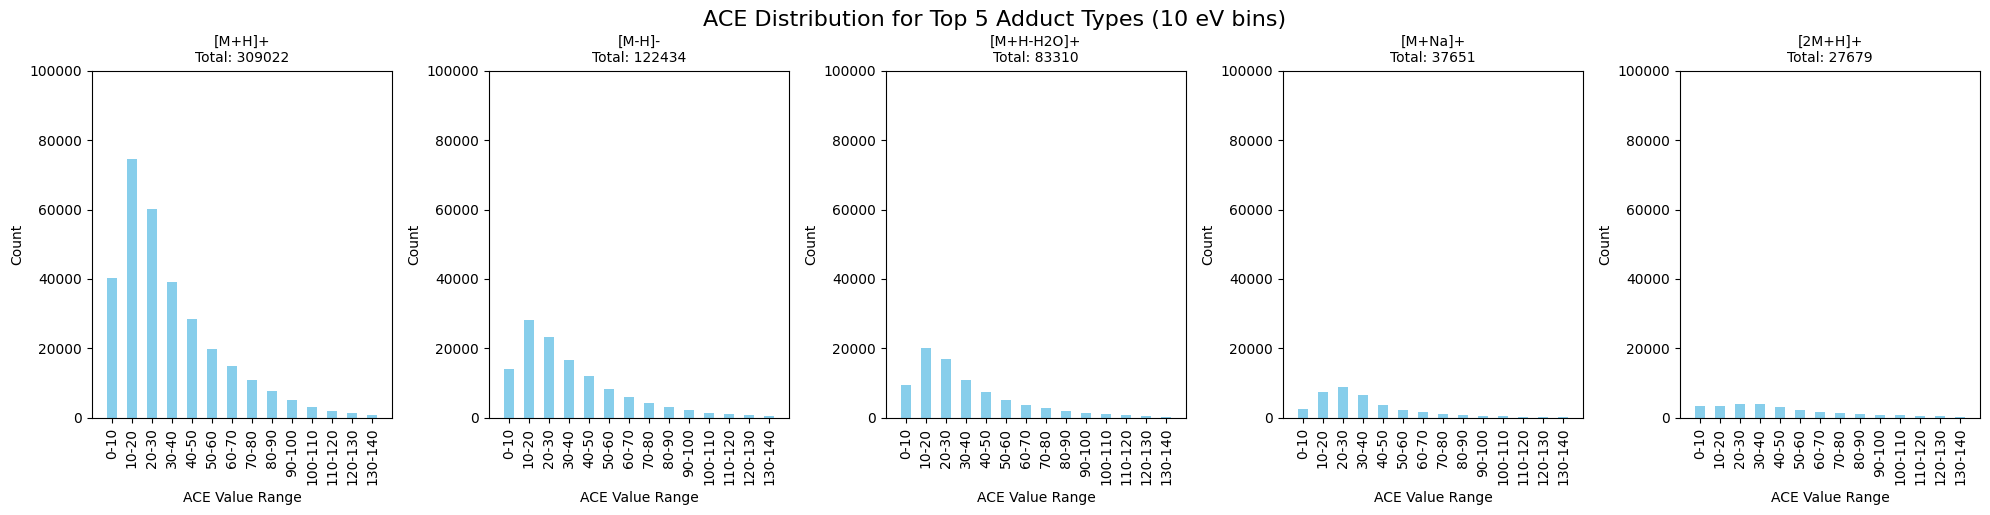

In [9]:
import numpy as np

prec_type_ace_counts = nist_spectra_df.groupby(['prec_type', 'ace']).size().unstack(fill_value=0)

# Get the sum of spectra for each adduct type across all NCEs
adduct_totals = prec_type_ace_counts.sum(axis=1).sort_values(ascending=False)
top_10_adducts = adduct_totals.head(5).index

# Create a figure with 10 subplots (2 rows, 5 columns)
fig, axes = plt.subplots(1, 5, figsize=(20, 5), sharey=False)
axes = axes.flatten()

# Define ACE bins
ace_bin_size = 10
bins = np.arange(0, 150, ace_bin_size)
bin_labels = [f"{b}-{b+ace_bin_size}" for b in bins[:-1]]

# Plot data for each of the top 10 adducts
for i, adduct in enumerate(top_10_adducts):
    # Get the NCE counts for this adduct
    nce_data = prec_type_ace_counts.loc[adduct]
    
    # Create binned data
    binned_data = {}
    for col in nce_data.index:
        bin_idx = np.digitize(col, bins) - 1
        if bin_idx >= len(bin_labels):
            continue
        bin_name = bin_labels[bin_idx]
        if bin_name not in binned_data:
            binned_data[bin_name] = 0
        binned_data[bin_name] += nce_data[col]
    
    # Convert to Series
    binned_series = pd.Series(binned_data)
    # Filter out zero counts
    binned_series = binned_series[binned_series > 0]
    
    # Plot on the corresponding subplot
    ax = axes[i]
    binned_series.plot(kind='bar', ax=ax, color='skyblue')
    
    # Set labels and title
    ax.set_title(f"{adduct}", fontsize=10)
    ax.set_xlabel('ACE Value Range')
    ax.set_ylabel('Count')
    ax.tick_params(axis='x', rotation=90)
    ax.set_ylim(0, 100_000)
    
    ax.set_xlim(-1, 14)
    # Add total count in the title
    total = binned_series.sum()
    ax.set_title(f"{adduct}\nTotal: {total}", fontsize=10)

# Adjust layout
plt.tight_layout()
plt.suptitle(f'ACE Distribution for Top 5 Adduct Types ({ace_bin_size} eV bins)', fontsize=16, y=1.02)
plt.show()

In [10]:
nist_mol_df = pd.read_pickle('../../data/proc/nist20/mol_df.pkl')
nist_mol_df.drop(['mol'], axis=1, inplace=True)
nist_mol_df.head()

,smiles,mol_id,inchikey_s,scaffold,formula,inchi,mw,exact_mw,num_atoms,num_bonds,charge,single_mol,num_radicals
0,*C1(C)C(OC2OC(CO)C(O)C(OC3OC(CO)C(O)C(O)C3O)C2...,0,,O=C(OC1CCCCO1)C12CCCCC1C1=CCC3C4CCC(OC5CC(OC6C...,C47H75*O19,,944.098,943.490255,67,74,0,True,0
1,BrC1=CCN(Cc2ccccc2)CC1,1,PMICKOYXYJSXPC,C1=CCN(Cc2ccccc2)CC1,C12H14BrN,InChI=1S/C12H14BrN/c13-12-6-8-14(9-7-12)10-11-...,252.155,251.030962,14,15,0,True,0
2,BrC1CCCCCC(Br)C12OCCO2,2,OQCIVOUQHXUSEL,C1CCCC2(CCC1)OCCO2,C10H16Br2O2,InChI=1S/C10H16Br2O2/c11-8-4-2-1-3-5-9(12)10(8...,328.044,325.951704,14,15,0,True,0
3,BrC1CCN(Cc2ccccc2)C1,3,VOXJTPBOJBQGSL,c1ccc(CN2CCCC2)cc1,C11H14BrN,InChI=1S/C11H14BrN/c12-11-6-7-13(9-11)8-10-4-2...,240.144,239.030962,13,14,0,True,0
4,BrC=C(c1ccccc1)c1ccccc1,4,QRDVTIMUEDYLOC,C=C(c1ccccc1)c1ccccc1,C14H11Br,InChI=1S/C14H11Br/c15-11-14(12-7-3-1-4-8-12)13...,259.146,258.004412,15,16,0,True,0


In [11]:
nist_df = nist_spectra_df.merge(nist_mol_df, on='mol_id', how='left')
nist_df.head()

,spec_id,mol_id,prec_type,inst_type,frag_mode,spec_type,ion_mode,dset,dset_spec_id,col_gas,...,scaffold,formula,inchi,mw,exact_mw,num_atoms,num_bonds,charge,single_mol,num_radicals
0,0,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035166,N2,...,,C81H142O17P2,InChI=1S/C81H142O17P2/c1-5-9-13-17-21-25-29-33...,1449.958,1448.972226,100,99,0,True,0
1,1,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035167,N2,...,,C81H142O17P2,InChI=1S/C81H142O17P2/c1-5-9-13-17-21-25-29-33...,1449.958,1448.972226,100,99,0,True,0
2,2,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035168,N2,...,,C81H142O17P2,InChI=1S/C81H142O17P2/c1-5-9-13-17-21-25-29-33...,1449.958,1448.972226,100,99,0,True,0
3,3,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035169,N2,...,,C81H142O17P2,InChI=1S/C81H142O17P2/c1-5-9-13-17-21-25-29-33...,1449.958,1448.972226,100,99,0,True,0
4,4,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035170,N2,...,,C81H142O17P2,InChI=1S/C81H142O17P2/c1-5-9-13-17-21-25-29-33...,1449.958,1448.972226,100,99,0,True,0


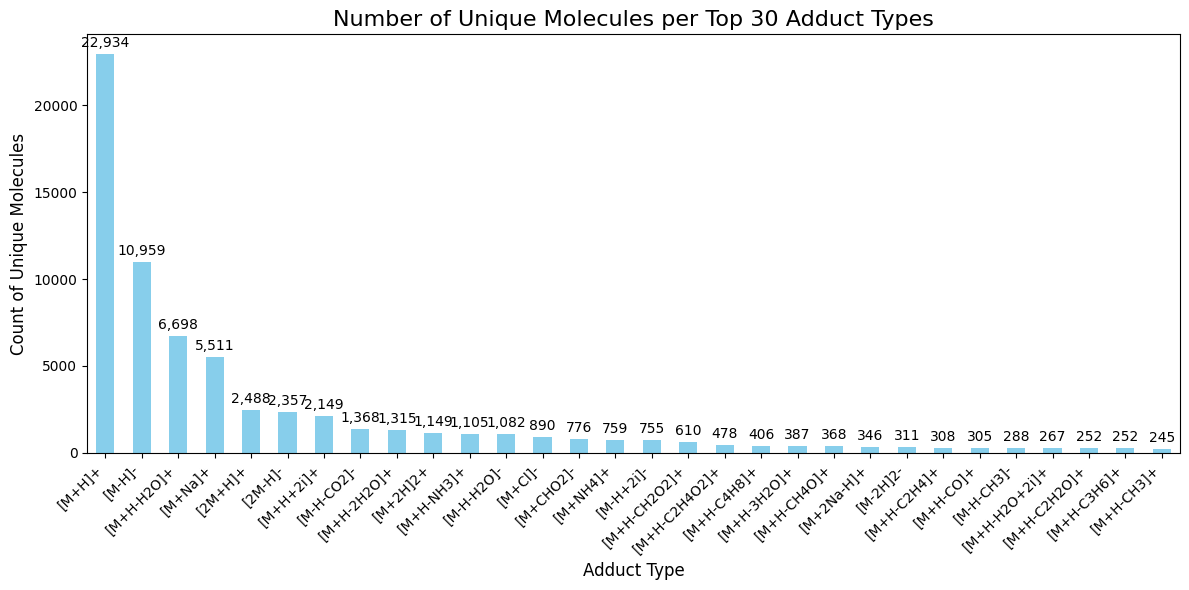

Number of unique molecules per adduct type:
prec_type
[M+H]+           22934
[M-H]-           10959
[M+H-H2O]+        6698
[M+Na]+           5511
[2M+H]+           2488
[2M-H]-           2357
[M+H+2i]+         2149
[M-H-CO2]-        1368
[M+H-2H2O]+       1315
[M+2H]2+          1149
[M+H-NH3]+        1105
[M-H-H2O]-        1082
[M+Cl]-            890
[M+CHO2]-          776
[M+NH4]+           759
[M-H+2i]-          755
[M+H-CH2O2]+       610
[M+H-C2H4O2]+      478
[M+H-C4H8]+        406
[M+H-3H2O]+        387
[M+H-CH4O]+        368
[M+2Na-H]+         346
[M-2H]2-           311
[M+H-C2H4]+        308
[M+H-CO]+          305
[M-H-CH3]-         288
[M+H-H2O+2i]+      267
[M+H-C2H2O]+       252
[M+H-C3H6]+        252
[M+H-CH3]+         245
Name: mol_id, dtype: int64


In [12]:
# Calculate the number of unique molecules per each adduct type
unique_mols_per_adduct = nist_df.groupby('prec_type')['mol_id'].nunique().sort_values(ascending=False)

# Get the top 10 adduct types by number of unique molecules
top_10_adducts_by_mols = unique_mols_per_adduct.head(30)

# Create a bar plot
plt.figure(figsize=(12, 6))
top_10_adducts_by_mols.plot(kind='bar', color='skyblue')

# Add labels and title
plt.title('Number of Unique Molecules per Top 30 Adduct Types', fontsize=16)
plt.xlabel('Adduct Type', fontsize=12)
plt.ylabel('Count of Unique Molecules', fontsize=12)
plt.xticks(rotation=45, ha='right')

# Add value labels on top of each bar
for i, v in enumerate(top_10_adducts_by_mols):
    plt.text(i, v + 0.01*max(top_10_adducts_by_mols), f"{v:,}", 
             ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

# Print the counts as well
print("Number of unique molecules per adduct type:")
print(top_10_adducts_by_mols)

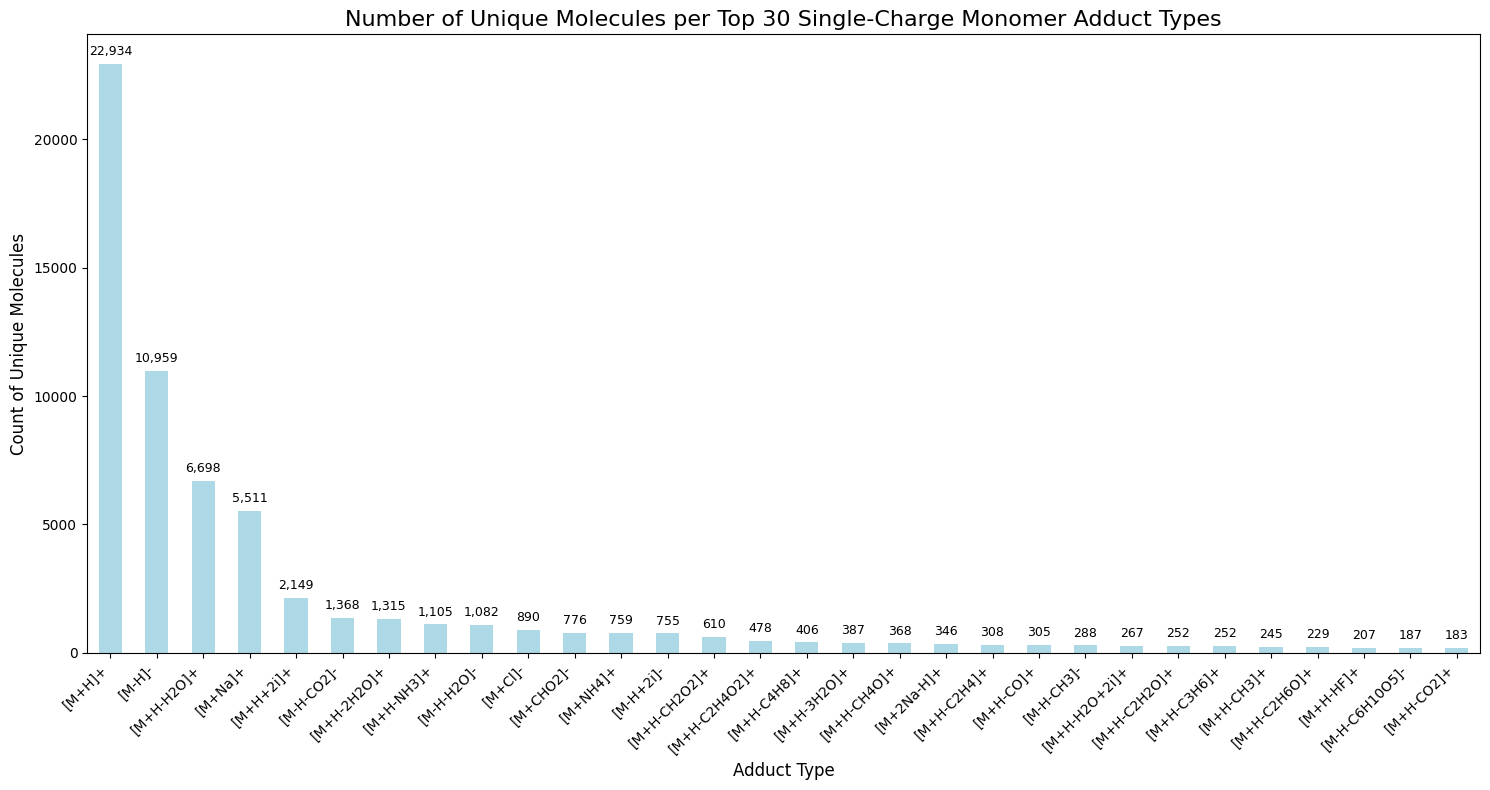

Number of unique molecules per single-charge monomer adduct type:
prec_type
[M+H]+            22934
[M-H]-            10959
[M+H-H2O]+         6698
[M+Na]+            5511
[M+H+2i]+          2149
[M-H-CO2]-         1368
[M+H-2H2O]+        1315
[M+H-NH3]+         1105
[M-H-H2O]-         1082
[M+Cl]-             890
[M+CHO2]-           776
[M+NH4]+            759
[M-H+2i]-           755
[M+H-CH2O2]+        610
[M+H-C2H4O2]+       478
[M+H-C4H8]+         406
[M+H-3H2O]+         387
[M+H-CH4O]+         368
[M+2Na-H]+          346
[M+H-C2H4]+         308
[M+H-CO]+           305
[M-H-CH3]-          288
[M+H-H2O+2i]+       267
[M+H-C2H2O]+        252
[M+H-C3H6]+         252
[M+H-CH3]+          245
[M+H-C2H6O]+        229
[M+H-HF]+           207
[M-H-C6H10O5]-      187
[M+H-CO2]+          183
Name: mol_id, dtype: int64


In [ ]:
# Filter out dimer adducts (those containing '2M') and multi-charge adducts
monomer_df = nist_df[
    (~nist_df['prec_type'].str.contains('2M')) & 
    (~nist_df['prec_type'].str.contains(']2+')) & 
    (~nist_df['prec_type'].str.contains(']2-')) & 
    (~nist_df['prec_type'].str.contains(']3+')) & 
    (~nist_df['prec_type'].str.contains(']3-'))
]

# Calculate the number of unique molecules per each adduct type (excluding dimers and multi-charge)
unique_mols_per_monomer_adduct = monomer_df.groupby('prec_type')['mol_id'].nunique().sort_values(ascending=False)

# Get the top 30 adduct types by number of unique molecules
top_30_monomer_adducts = unique_mols_per_monomer_adduct.head(30)

# Create a bar plot
plt.figure(figsize=(15, 8))
top_30_monomer_adducts.plot(kind='bar', color='lightblue')

# Add labels and title
plt.title('Number of Unique Molecules per Top 30 Single-Charge Monomer Adduct Types', fontsize=16)
plt.xlabel('Adduct Type', fontsize=12)
plt.ylabel('Count of Unique Molecules', fontsize=12)
plt.xticks(rotation=45, ha='right')

# Add value labels on top of each bar
for i, v in enumerate(top_30_monomer_adducts):
    plt.text(i, v + 0.01*max(top_30_monomer_adducts), f"{v:,}", 
             ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

# Print the counts as well
print("Number of unique molecules per single-charge monomer adduct type:")
print(top_30_monomer_adducts)

In [14]:
frag_dp = '../../data/frag/nist20_ma_mi_d3_h4_isoFalse'
spec_frag_stats_df = pd.read_pickle(f'{frag_dp}/spec_stats_df.pkl')
spec_frag_stats_df = spec_frag_stats_df.merge(nist_df[['spec_id', 'prec_type','ace','nce','peaks']], on='spec_id', how='left')
spec_frag_stats_df.dropna(subset=['ace'], inplace=True)
spec_frag_stats_df.dropna(subset=['nce'], inplace=True)
spec_frag_stats_df.head()

,spec_id,mol_id,recall_0.01_h1,wrecall_0.01_h1,prec_0.01_h1,ppt_peak_0.01_h1,ppt_formula_0.01_h1,prec_recall_0.01_h1,prec_spec_recall_0.01_h1,recall_0.01_h2,...,depth,formula_redundancy,dag_num_edges,dag_num_nodes,dag_sparsity,dag_num_nodes_nb,prec_type,ace,nce,peaks
0,7,10998,0.200000,0.816530,0.000482,1.0,1.0,1.0,1.0,0.600000,...,3,80.064123,597904,71201,0.000236,-1,[M+Na]+,23.0,8.0,"[(599.5, 41.06), (873.47, 47.75), (1470.95, 86..."
1,8,10998,0.200000,0.757691,0.000482,1.0,1.0,1.0,1.0,0.600000,...,3,80.064123,597904,71201,0.000236,-1,[M+Na]+,30.0,10.0,"[(599.49, 52.95), (601.51, 54.15), (873.46, 13..."
2,9,10998,0.200000,0.691273,0.000482,1.0,1.0,1.0,1.0,0.400000,...,3,80.064123,597904,71201,0.000236,-1,[M+Na]+,35.0,12.0,"[(274.97, 74.23), (599.5, 79.22), (601.52, 50...."
3,15,10998,0.142857,0.028636,0.000482,1.0,1.0,1.0,0.0,0.285714,...,3,80.064123,597904,71201,0.000236,-1,[M-H]-,20.0,7.0,"[(29.69, 24.38), (279.24, 44.56), (415.23, 34...."
4,16,10998,0.333333,0.048806,0.000964,1.0,1.0,1.0,0.0,0.500000,...,3,80.064123,597904,71201,0.000236,-1,[M-H]-,25.0,9.0,"[(153.0, 26.67), (279.24, 45.45), (415.23, 31...."


/tmp/ipykernel_1391808/2227257683.py:29: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mean_recall = selected_df.groupby(pd.cut(selected_df['ace'], ace_bins))[col].mean()
/tmp/ipykernel_1391808/2227257683.py:29: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mean_recall = selected_df.groupby(pd.cut(selected_df['ace'], ace_bins))[col].mean()
/tmp/ipykernel_1391808/2227257683.py:29: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warnin

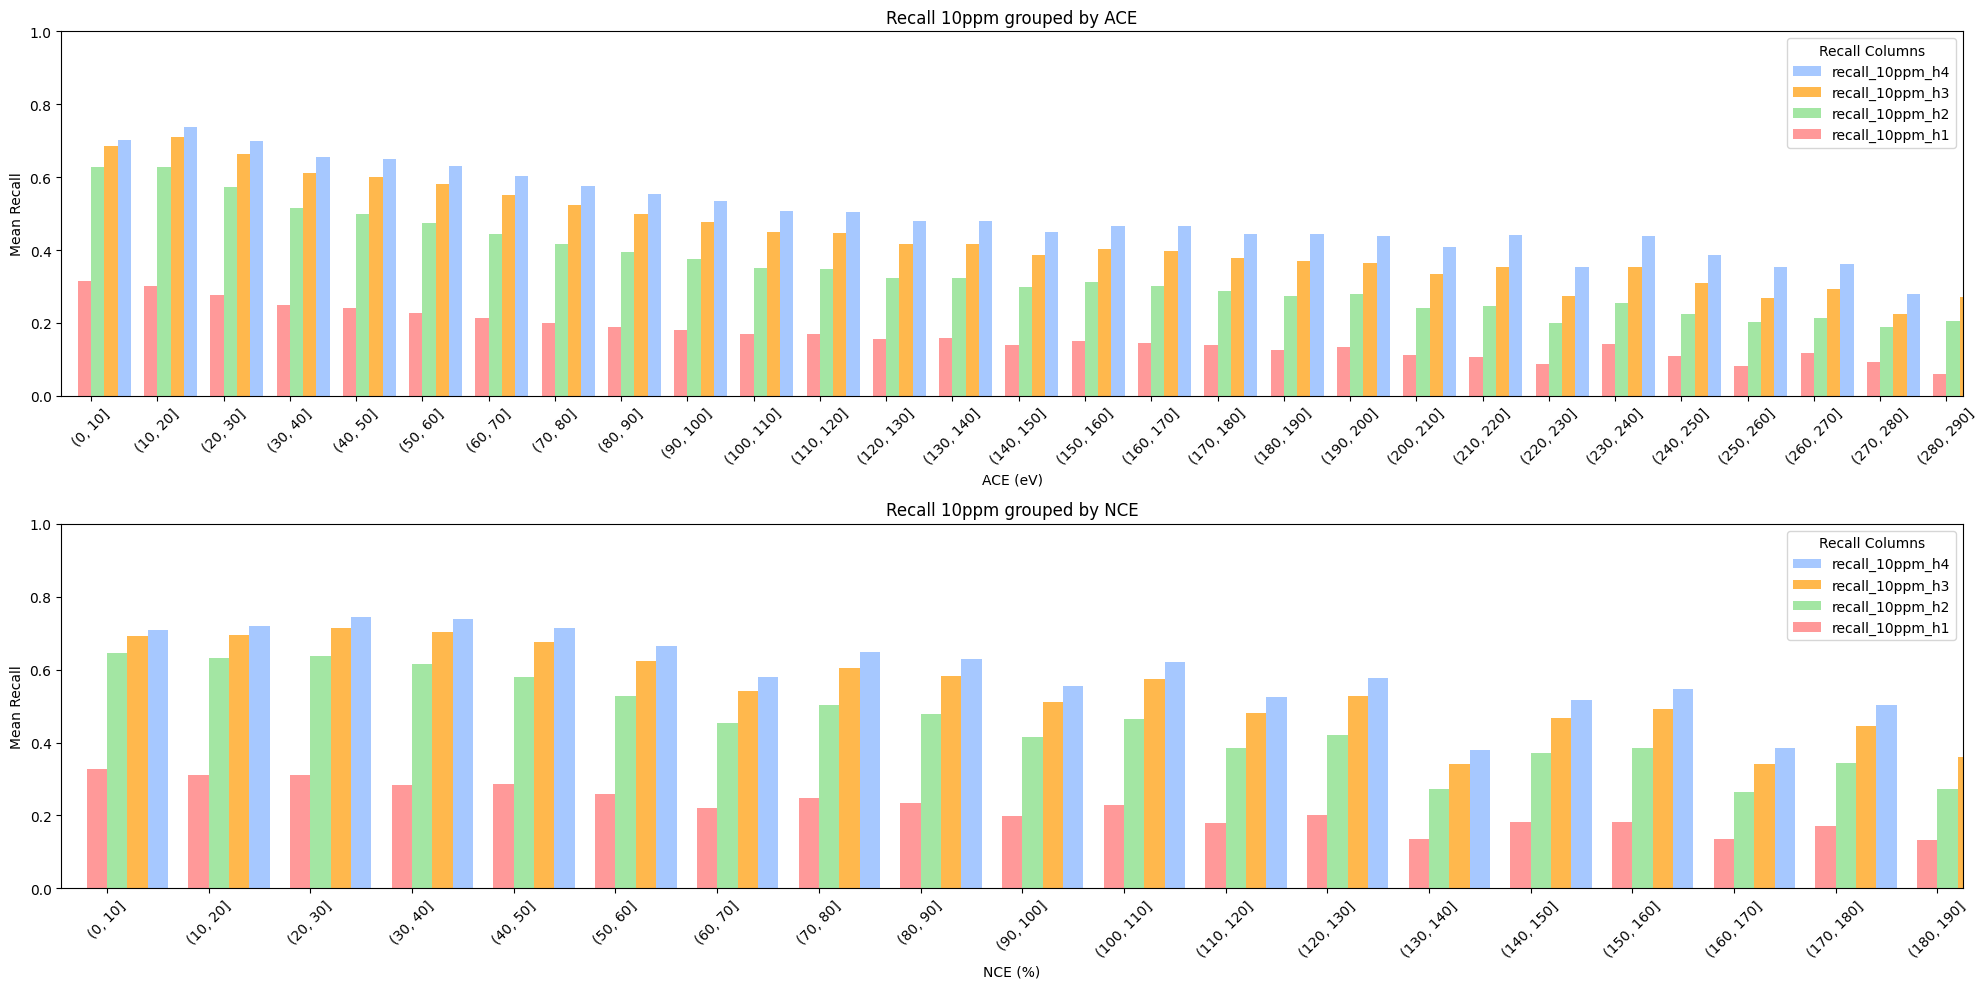

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Filter the dataframe for the specified precursor type
selected_df = spec_frag_stats_df[spec_frag_stats_df['prec_type'] == '[M+H]+']

# Define the columns to plot
recall_columns = ['recall_10ppm_h1', 'recall_10ppm_h2', 'recall_10ppm_h3', 'recall_10ppm_h4']
recall_columns.reverse()

# Define ACE and NCE bins
ace_bin_size = 10
nce_bin_size = 10
ace_bins = np.arange(0, 300, ace_bin_size)
nce_bins = np.arange(0, 200, nce_bin_size)

# Create a figure with 2 subplots (rows=2, columns=1)
fig, axes = plt.subplots(2, 1, figsize=(20, 10))
axes = axes.flatten()

# New color choices (You can use color names, hex values, or RGB tuples)
colors = ['#a6c8ff', '#ffb84d', '#a3e6a3', '#ff9999']  # Light Blue, Light Orange, Light Green, Light Red

# Plot histograms for each recall column grouped by ACE
ax = axes[0]
width = 0.2  # Bar width for separation
for i, col in enumerate(recall_columns):
    mean_recall = selected_df.groupby(pd.cut(selected_df['ace'], ace_bins))[col].mean()
    mean_recall.plot(kind='bar', ax=ax, color=colors[i], width=width, position=i-2)

# Set labels and title for ACE plot
ax.set_title(f'Recall 10ppm grouped by ACE')
ax.set_xlabel('ACE (eV)')
ax.set_ylabel('Mean Recall')
ax.tick_params(axis='x', rotation=45)
ax.set_ylim(0, 1)
ax.legend(recall_columns, title="Recall Columns")

# Plot histograms for each recall column grouped by NCE
ax = axes[1]
for i, col in enumerate(recall_columns):
    mean_recall = selected_df.groupby(pd.cut(selected_df['nce'], nce_bins))[col].mean()
    mean_recall.plot(kind='bar', ax=ax, color=colors[i], width=width, position=i-2)

# Set labels and title for NCE plot
ax.set_title(f'Recall 10ppm grouped by NCE')
ax.set_xlabel('NCE (%)')
ax.set_ylabel('Mean Recall')
ax.tick_params(axis='x', rotation=45)
ax.set_ylim(0, 1)
ax.legend(recall_columns, title="Recall Columns")

# Adjust layout to prevent overlapping
plt.tight_layout()
plt.show()

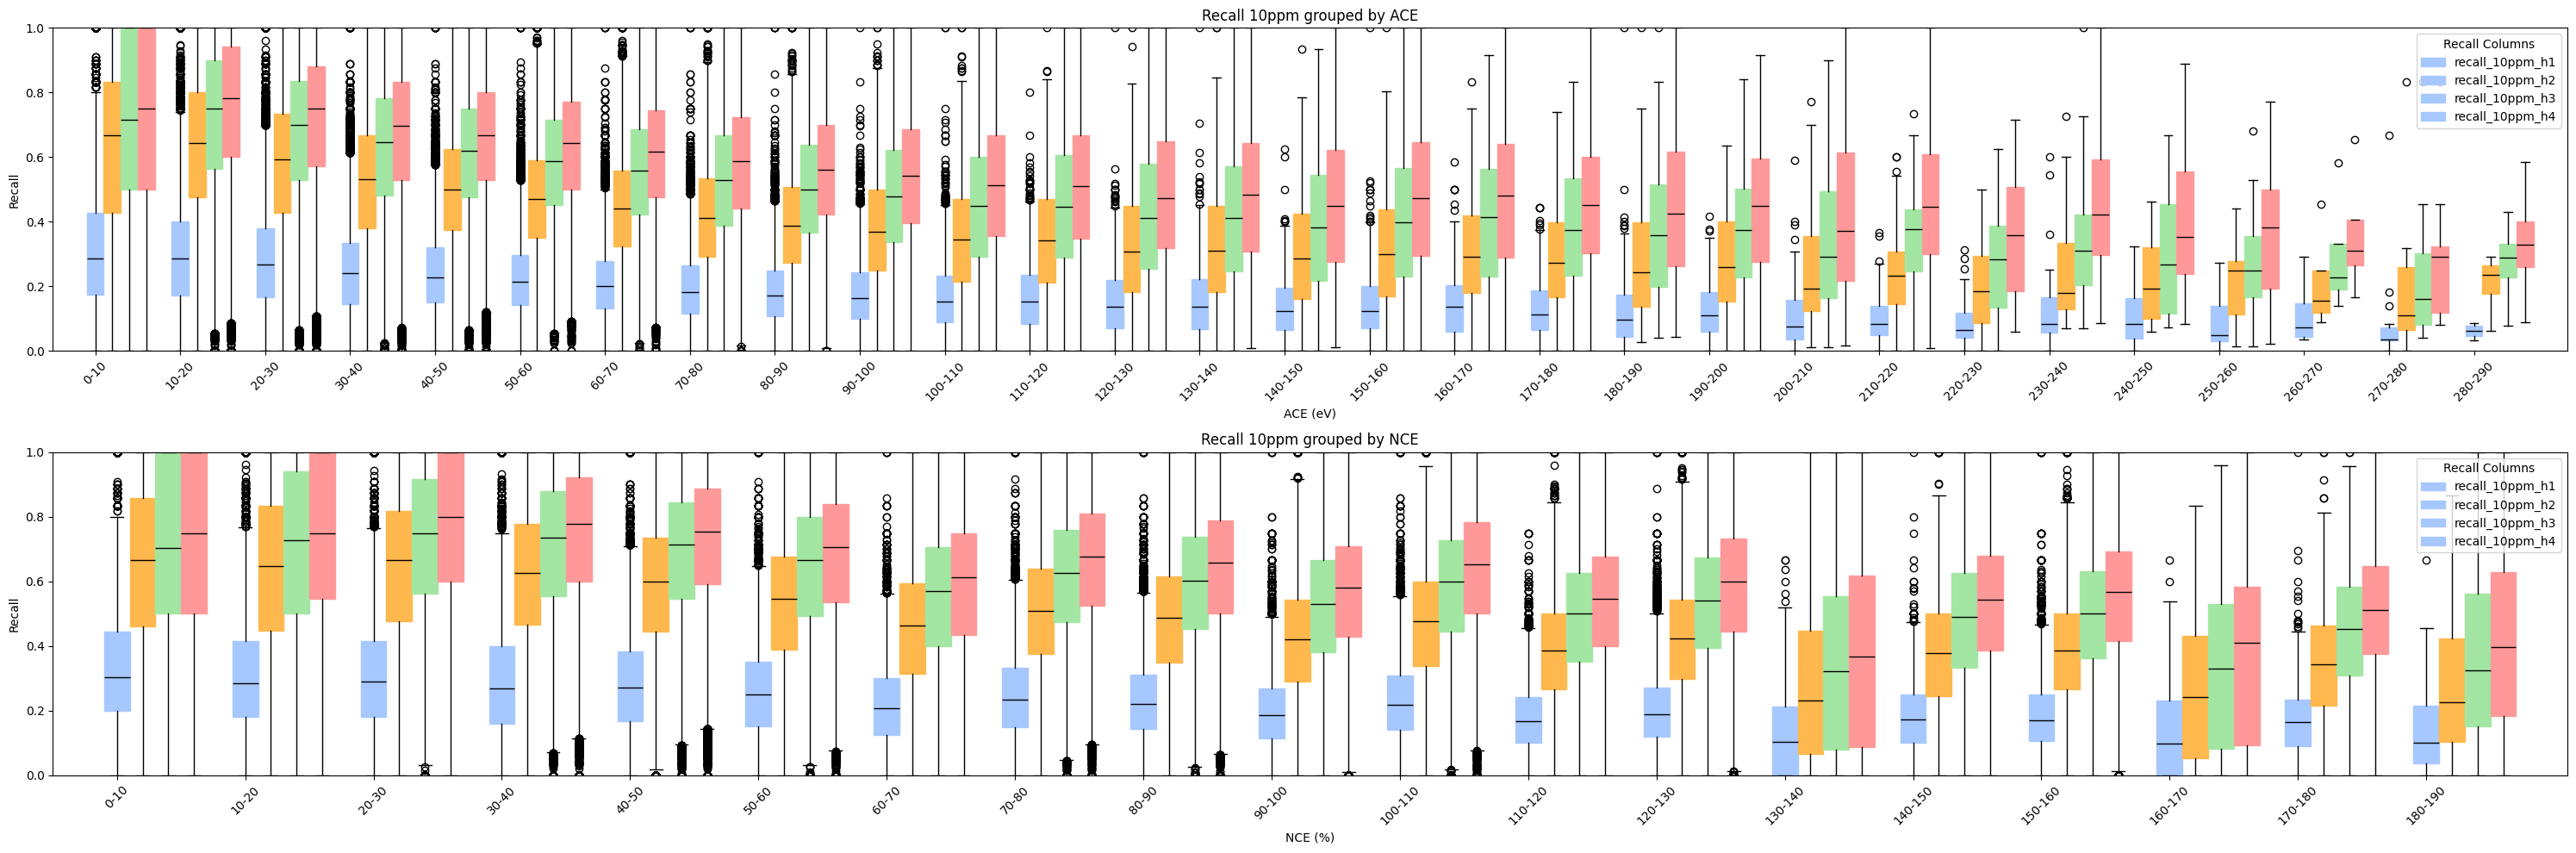

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Filter the dataframe for the specified precursor type
selected_df = spec_frag_stats_df[spec_frag_stats_df['prec_type'] == '[M+H]+']

# Define the columns to plot
recall_columns = ['recall_10ppm_h1', 'recall_10ppm_h2', 'recall_10ppm_h3', 'recall_10ppm_h4']

# Define ACE and NCE bins
ace_bin_size = 10
nce_bin_size = 10
ace_bins = np.arange(0, 300, ace_bin_size)
nce_bins = np.arange(0, 200, nce_bin_size)

# Create a wider figure with 2 subplots (rows=2, columns=1)
fig, axes = plt.subplots(2, 1, figsize=(30, 10))  # Increased the width
axes = axes.flatten()

# Lighter color choices (lighter shades of blue, orange, green, and red)
colors = ['#a6c8ff', '#ffb84d', '#a3e6a3', '#ff9999']  # Light Blue, Light Orange, Light Green, Light Red

# Plot box plots for each recall column grouped by ACE
ax = axes[0]
for i, col in enumerate(recall_columns):
    # Group by ACE bins and extract the corresponding values for boxplot
    ace_labels = pd.cut(selected_df['ace'], ace_bins)  # This creates the bin intervals
    grouped_recall = [selected_df[ace_labels == interval][col] for interval in ace_labels.cat.categories]
    
    ax.boxplot(grouped_recall, positions=np.arange(len(grouped_recall)) + (i * 0.2), widths=0.2, 
               patch_artist=True, boxprops=dict(facecolor=colors[i], color=colors[i]),
               medianprops=dict(color='black'))

# Set labels and title for ACE plot
ax.set_title(f'Recall 10ppm grouped by ACE')
ax.set_xlabel('ACE (eV)')
ax.set_ylabel('Recall')
ax.set_xticks(np.arange(len(ace_bins) - 1))
ax.set_xticklabels([f'{int(ace_bins[i])}-{int(ace_bins[i + 1])}' for i in range(len(ace_bins) - 1)], rotation=45)
ax.set_ylim(0, 1)
ax.legend(recall_columns, title="Recall Columns")

# Plot box plots for each recall column grouped by NCE
ax = axes[1]
for i, col in enumerate(recall_columns):
    # Group by NCE bins and extract the corresponding values for boxplot
    nce_labels = pd.cut(selected_df['nce'], nce_bins)  # This creates the bin intervals
    grouped_recall = [selected_df[nce_labels == interval][col] for interval in nce_labels.cat.categories]
    
    ax.boxplot(grouped_recall, positions=np.arange(len(grouped_recall)) + (i * 0.2), widths=0.2, 
               patch_artist=True, boxprops=dict(facecolor=colors[i], color=colors[i]),
               medianprops=dict(color='black'))

# Set labels and title for NCE plot
ax.set_title(f'Recall 10ppm grouped by NCE')
ax.set_xlabel('NCE (%)')
ax.set_ylabel('Recall')
ax.set_xticks(np.arange(len(nce_bins) - 1))
ax.set_xticklabels([f'{int(nce_bins[i])}-{int(nce_bins[i + 1])}' for i in range(len(nce_bins) - 1)], rotation=45)
ax.set_ylim(0, 1)
ax.legend(recall_columns, title="Recall Columns")

# Adjust layout to prevent overlapping
plt.tight_layout()
plt.show()

In [17]:
spec_frag_stats_df[(spec_frag_stats_df['ace'] <= 1.0) & (spec_frag_stats_df['recall_0.01_h4'] <= 1.0)]

,spec_id,mol_id,recall_0.01_h1,wrecall_0.01_h1,prec_0.01_h1,ppt_peak_0.01_h1,ppt_formula_0.01_h1,prec_recall_0.01_h1,prec_spec_recall_0.01_h1,recall_0.01_h2,...,depth,formula_redundancy,dag_num_edges,dag_num_nodes,dag_sparsity,dag_num_nodes_nb,prec_type,ace,nce,peaks
1051,180080,30902,0.500000,0.926355,0.040000,1.0,1.0,1.0,1.0,1.000000,...,3,2.577465,224,61,0.122404,-1,[M-H]-,1.0,5.0,"[(67.019, 79.42), (111.0087, 999.0)]"
1084,180192,8630,0.333333,0.806126,0.015152,1.0,1.0,1.0,1.0,1.000000,...,3,4.323887,662,158,0.053374,-1,[M-H]-,0.0,2.0,"[(117.0707, 20.38), (119.0864, 219.88), (163.0..."
1085,180193,8630,0.333333,0.697445,0.015152,1.0,1.0,1.0,1.0,1.000000,...,3,4.323887,662,158,0.053374,-1,[M-H]-,1.0,4.0,"[(117.0708, 69.03), (119.0864, 364.34), (163.0..."
1380,181957,1842,0.333333,0.656416,0.046512,1.0,1.0,1.0,1.0,0.666667,...,3,3.459016,584,102,0.113376,-1,[M+H]+,0.0,2.0,"[(99.044, 26.67), (113.0597, 96.8), (141.0548,..."
1381,181958,1842,0.400000,0.578453,0.046512,1.0,1.0,1.0,1.0,0.800000,...,3,3.459016,584,102,0.113376,-1,[M+H]+,1.0,2.0,"[(99.0438, 76.02), (113.0596, 162.94), (141.05..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
553083,1000116,30857,0.277778,0.647030,0.030864,1.0,1.0,1.0,1.0,0.722222,...,3,2.356531,1362,360,0.021077,-1,[M+Na]+,1.0,2.0,"[(114.0316, 2.6), (143.0106, 72.03), (144.014,..."
553346,1000504,20026,0.250000,0.069657,0.027027,1.0,1.0,1.0,1.0,0.583333,...,3,4.156627,1328,311,0.027549,-1,[M+H]+,1.0,2.0,"[(109.0651, 29.07), (153.0007, 706.39), (154.0..."
553361,1000529,20026,0.384615,0.862951,0.045045,1.0,1.0,1.0,1.0,0.846154,...,3,4.156627,1328,311,0.027549,-1,[M-H]-,1.0,2.0,"[(109.0123, 1.7), (123.9996, 1.2), (139.023, 2..."
553392,1000585,16394,0.238095,0.650717,0.024752,1.0,1.0,1.0,1.0,0.333333,...,3,3.071636,1666,452,0.016345,-1,[M-H]-,1.0,2.0,"[(252.0219, 33.17), (253.0253, 3.6), (256.0167..."
